# Geometric Brownian Motion

This notebook introduces Geometric Brownian Motion as a model for financial asset prices.

Unlike an additive random walk, GBM models proportional price changes and guarantees that simulated prices remain positive.

The discrete simulation equation is:

# Geometric Brownian Motion

This notebook introduces Geometric Brownian Motion as a model for financial asset prices.

Unlike an additive random walk, GBM models proportional price changes and guarantees that simulated prices remain positive.

The discrete simulation equation is:

\[
S_{t+\Delta t}
=
S_t
\exp\left[
\left(\mu-\frac{\sigma^2}{2}\right)\Delta t
+
\sigma\sqrt{\Delta t}Z_t
\right]
\]

where \(Z_t\) is a standard normal random variable.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
initial_price = 100
annual_drift = 0.08
annual_volatility = 0.20

trading_days = 252
time_horizon = 1
dt = 1 / trading_days

n_steps = int(trading_days * time_horizon)

In [3]:
time = np.linspace(
    0,
    time_horizon,
    n_steps + 1
)

time[:5]

array([0.        , 0.00396825, 0.00793651, 0.01190476, 0.01587302])

In [4]:
normal_shocks = rng.normal(
    loc=0,
    scale=1,
    size=n_steps
)

normal_shocks[:10]

array([ 0.30471708, -1.03998411,  0.7504512 ,  0.94056472, -1.95103519,
       -1.30217951,  0.1278404 , -0.31624259, -0.01680116, -0.85304393])

In [5]:
log_returns = (
    annual_drift - 0.5 * annual_volatility**2
) * dt + annual_volatility * np.sqrt(dt) * normal_shocks

log_returns[:10]

array([ 4.07716959e-03, -1.28644729e-02,  9.69289160e-03,  1.20880968e-02,
       -2.43426377e-02, -1.61678245e-02,  1.84873293e-03, -3.74618692e-03,
        2.64205500e-05, -1.05092480e-02])

In [6]:
cumulative_log_returns = np.concatenate(
    ([0], np.cumsum(log_returns))
)

prices = initial_price * np.exp(cumulative_log_returns)

prices[:10]

array([100.        , 100.40854926,  99.12511922, 100.09059984,
       101.30784698,  98.87152039,  97.28583607,  97.46585796,
        97.10141569,  97.1039812 ])

In [7]:
gbm_data = pd.DataFrame({
    "time": time,
    "price": prices
})

gbm_data.head()

,time,price
0,0.000000,100.000000
1,0.003968,100.408549
2,0.007937,99.125119
3,0.011905,100.090600
4,0.015873,101.307847


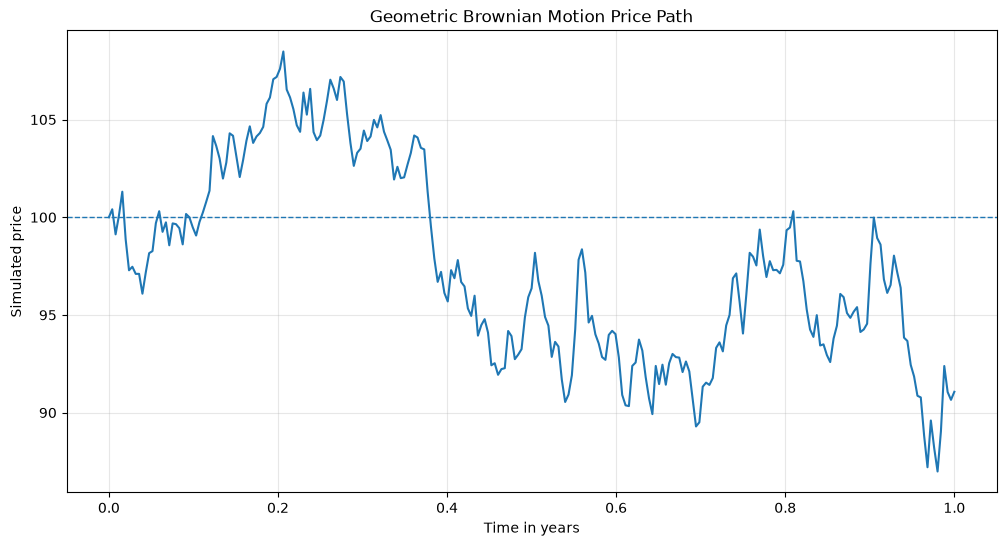

In [8]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    gbm_data["time"],
    gbm_data["price"],
    linewidth=1.5
)

ax.axhline(
    y=initial_price,
    linestyle="--",
    linewidth=1
)

ax.set_title("Geometric Brownian Motion Price Path")
ax.set_xlabel("Time in years")
ax.set_ylabel("Simulated price")
ax.grid(alpha=0.3)

plt.show()

In [9]:
simple_returns = prices[1:] / prices[:-1] - 1

simple_returns[:10]

array([ 4.08549255e-03, -1.27820793e-02,  9.74001982e-03,  1.21614531e-02,
       -2.40487452e-02, -1.60378267e-02,  1.85044289e-03, -3.73917872e-03,
        2.64208991e-05, -1.04542188e-02])

In [10]:
returns_data = pd.DataFrame({
    "simple_return": simple_returns,
    "log_return": log_returns
})

returns_data.head()

,simple_return,log_return
0,0.004085,0.004077
1,-0.012782,-0.012864
2,0.009740,0.009693
3,0.012161,0.012088
4,-0.024049,-0.024343


In [11]:
reconstructed_log_returns = np.log1p(simple_returns)

maximum_difference = np.max(
    np.abs(log_returns - reconstructed_log_returns)
)

maximum_difference

np.float64(3.3480163086352377e-16)

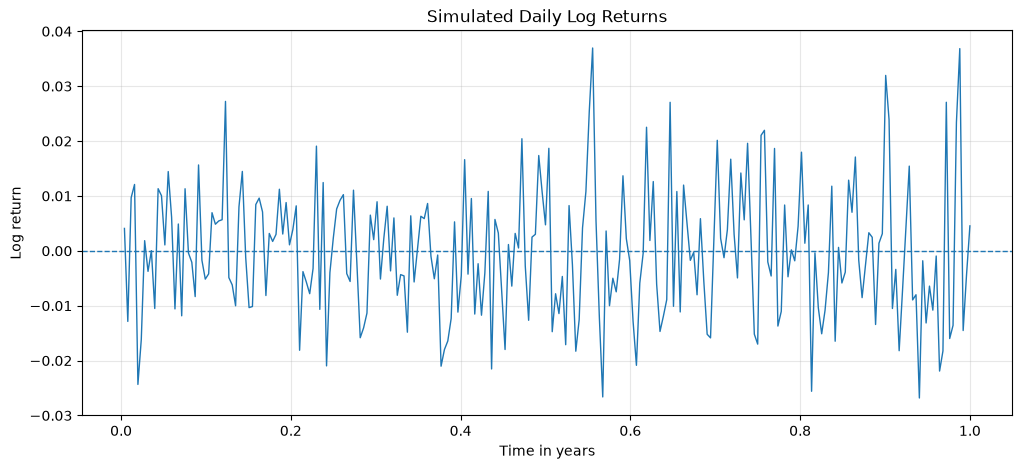

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    time[1:],
    log_returns,
    linewidth=1
)

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

ax.set_title("Simulated Daily Log Returns")
ax.set_xlabel("Time in years")
ax.set_ylabel("Log return")
ax.grid(alpha=0.3)

plt.show()

In [13]:
path_summary = pd.Series({
    "initial_price": prices[0],
    "final_price": prices[-1],
    "minimum_price": prices.min(),
    "maximum_price": prices.max(),
    "total_simple_return": prices[-1] / prices[0] - 1,
    "total_log_return": np.log(prices[-1] / prices[0]),
    "mean_daily_log_return": log_returns.mean(),
    "daily_log_return_std": log_returns.std()
})

path_summary

initial_price            100.000000
final_price               91.067375
minimum_price             86.987328
maximum_price            108.484221
total_simple_return       -0.089326
total_log_return          -0.093571
mean_daily_log_return     -0.000371
daily_log_return_std       0.011789
dtype: float64

## Interpretation of a single GBM path

The simulated path represents only one possible evolution of the asset price.

The drift parameter controls the average long-term growth rate, while volatility controls the magnitude of random fluctuations.

Over short horizons, the random component generally dominates the drift because the deterministic term scales with \(\Delta t\), whereas the stochastic term scales with \(\sqrt{\Delta t}\).

An important property of Geometric Brownian Motion is that prices remain strictly positive because they are obtained through an exponential transformation.

In [14]:
n_simulations = 10_000

all_normal_shocks = rng.normal(
    loc=0,
    scale=1,
    size=(n_simulations, n_steps)
)

all_normal_shocks.shape

(10000, 252)

In [15]:
all_log_returns = (
    annual_drift - 0.5 * annual_volatility**2
) * dt + annual_volatility * np.sqrt(dt) * all_normal_shocks

all_cumulative_log_returns = np.concatenate(
    [
        np.zeros((n_simulations, 1)),
        np.cumsum(all_log_returns, axis=1)
    ],
    axis=1
)

all_prices = initial_price * np.exp(
    all_cumulative_log_returns
)

all_prices.shape

(10000, 253)

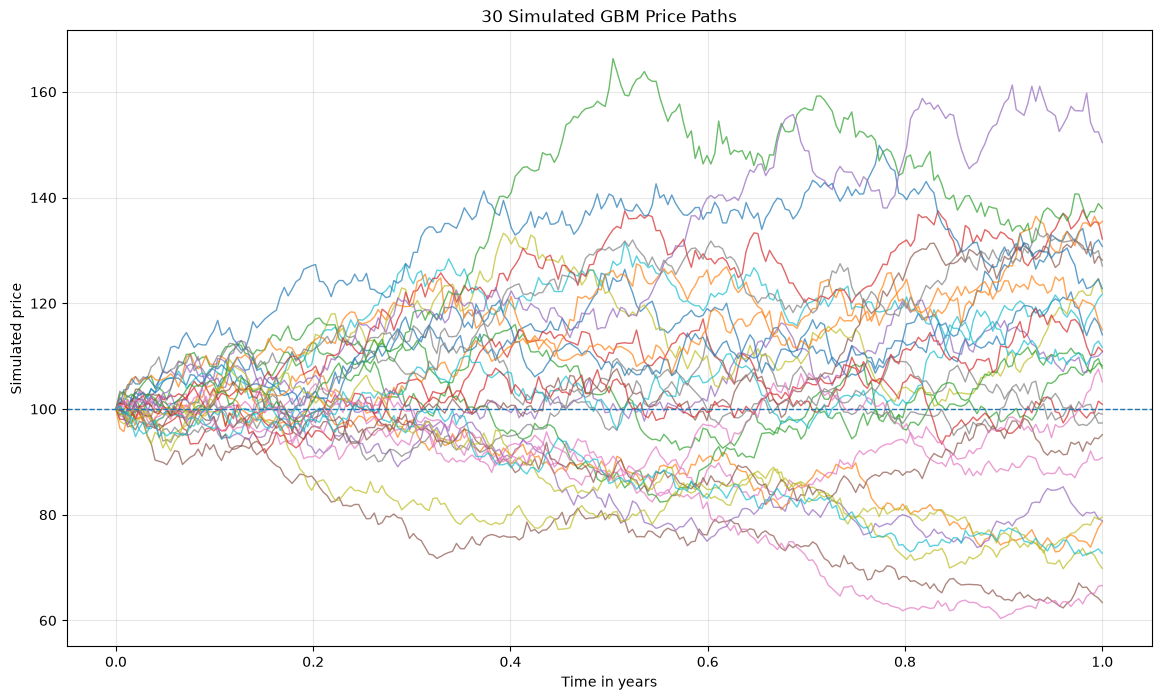

In [18]:
n_paths_to_plot = 30

fig, ax = plt.subplots(figsize=(14, 8))

for i in range(n_paths_to_plot):
    ax.plot(
        time,
        all_prices[i],
        linewidth=1,
        alpha=0.7
    )

ax.axhline(
    y=initial_price,
    linestyle="--",
    linewidth=1
)

ax.set_title(f"{n_paths_to_plot} Simulated GBM Price Paths")
ax.set_xlabel("Time in years")
ax.set_ylabel("Simulated price")
ax.grid(alpha=0.3)

plt.show()

In [19]:
final_prices = all_prices[:, -1]

pd.Series(final_prices).describe()

count    10000.000000
mean       108.523869
std         21.998523
min         36.572563
25%         93.005948
50%        106.273779
75%        121.805560
max        215.951048
dtype: float64

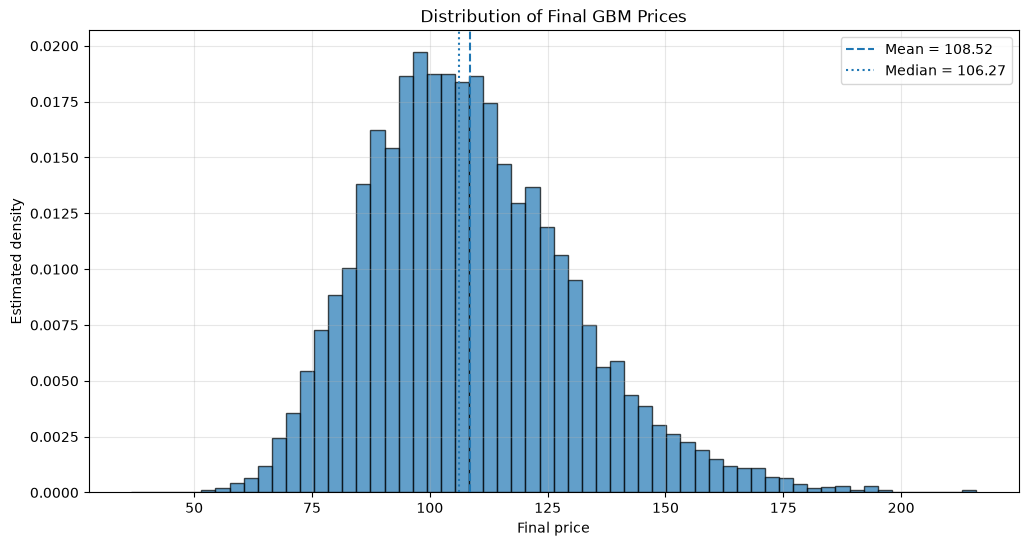

In [20]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    final_prices,
    bins=60,
    density=True,
    edgecolor="black",
    alpha=0.7
)

ax.axvline(
    final_prices.mean(),
    linestyle="--",
    label=f"Mean = {final_prices.mean():.2f}"
)

ax.axvline(
    np.median(final_prices),
    linestyle=":",
    label=f"Median = {np.median(final_prices):.2f}"
)

ax.set_title("Distribution of Final GBM Prices")
ax.set_xlabel("Final price")
ax.set_ylabel("Estimated density")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

Can see as expected we dont get a normal distribution but instead a lognormal distribution,
right skew

In [21]:
theoretical_mean_final_price = (
    initial_price
    * np.exp(annual_drift * time_horizon)
)

simulated_mean_final_price = final_prices.mean()

pd.Series({
    "simulated_mean_final_price": simulated_mean_final_price,
    "theoretical_mean_final_price": theoretical_mean_final_price,
    "absolute_difference": abs(
        simulated_mean_final_price
        - theoretical_mean_final_price
    )
})

simulated_mean_final_price      108.523869
theoretical_mean_final_price    108.328707
absolute_difference               0.195162
dtype: float64

Could easily be due to floating point precision of the computer

In [22]:
theoretical_median_final_price = initial_price * np.exp(
    (
        annual_drift
        - 0.5 * annual_volatility**2
    )
    * time_horizon
)

pd.Series({
    "simulated_median_final_price": np.median(final_prices),
    "theoretical_median_final_price": theoretical_median_final_price
})

simulated_median_final_price      106.273779
theoretical_median_final_price    106.183655
dtype: float64

In [23]:
probability_of_loss = np.mean(
    final_prices < initial_price
)

probability_of_gain = np.mean(
    final_prices > initial_price
)

pd.Series({
    "probability_of_loss": probability_of_loss,
    "probability_of_gain": probability_of_gain
})

probability_of_loss    0.3816
probability_of_gain    0.6184
dtype: float64

If this was the real Behaviour we would be incentivized to always invest in most everything, obviously still a naive representation, its not done to show this is how it actually works, but better than random walks

In [24]:
price_percentiles = np.percentile(
    final_prices,
    [5, 25, 50, 75, 95]
)

pd.Series(
    price_percentiles,
    index=[
        "5th percentile",
        "25th percentile",
        "median",
        "75th percentile",
        "95th percentile"
    ]
)

5th percentile      76.504729
25th percentile     93.005948
median             106.273779
75th percentile    121.805560
95th percentile    148.162711
dtype: float64

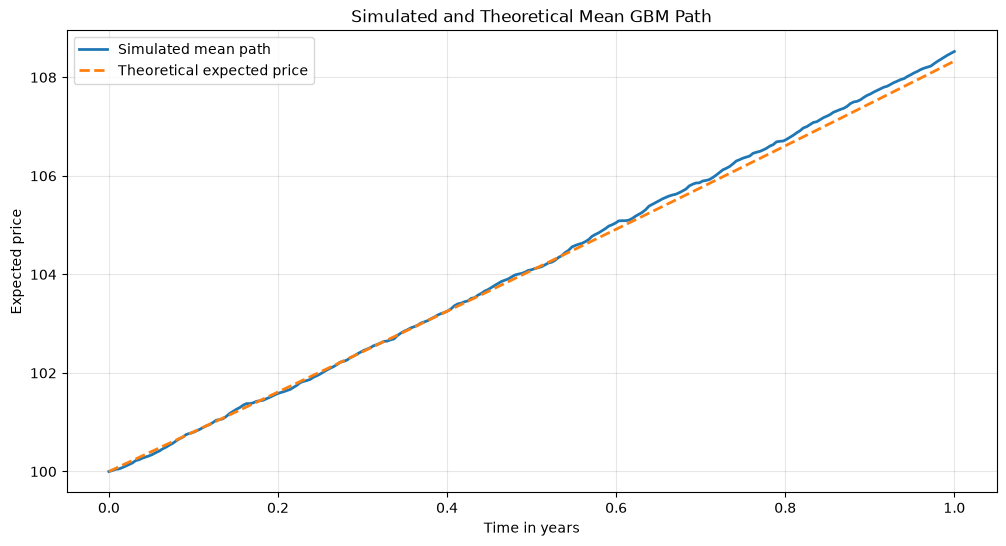

In [25]:
simulated_mean_path = all_prices.mean(axis=0)

theoretical_mean_path = (
    initial_price
    * np.exp(annual_drift * time)
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    time,
    simulated_mean_path,
    label="Simulated mean path",
    linewidth=2
)

ax.plot(
    time,
    theoretical_mean_path,
    linestyle="--",
    label="Theoretical expected price",
    linewidth=2
)

ax.set_title("Simulated and Theoretical Mean GBM Path")
ax.set_xlabel("Time in years")
ax.set_ylabel("Expected price")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

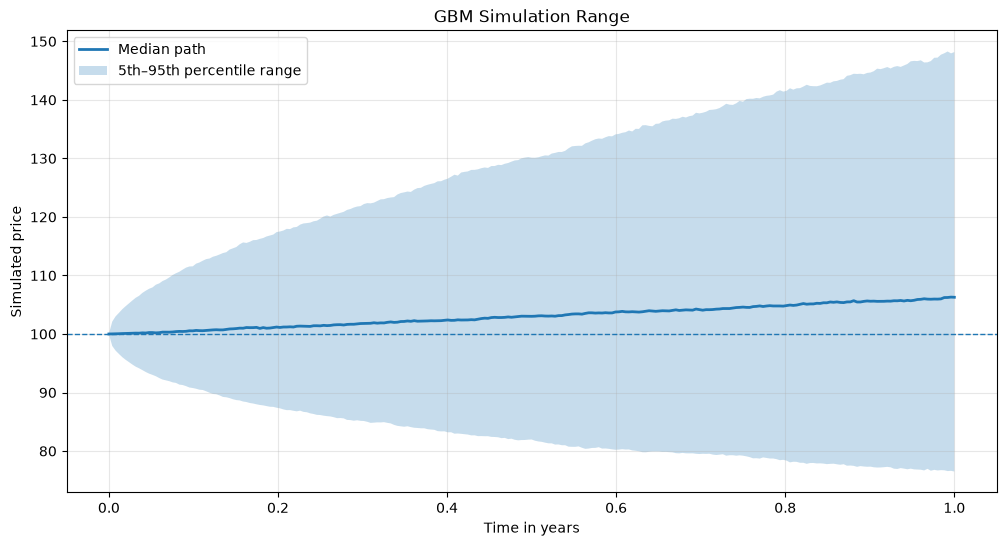

In [26]:
lower_band = np.percentile(
    all_prices,
    5,
    axis=0
)

median_path = np.percentile(
    all_prices,
    50,
    axis=0
)

upper_band = np.percentile(
    all_prices,
    95,
    axis=0
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    time,
    median_path,
    label="Median path",
    linewidth=2
)

ax.fill_between(
    time,
    lower_band,
    upper_band,
    alpha=0.25,
    label="5th–95th percentile range"
)

ax.axhline(
    y=initial_price,
    linestyle="--",
    linewidth=1
)

ax.set_title("GBM Simulation Range")
ax.set_xlabel("Time in years")
ax.set_ylabel("Simulated price")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

## Conclusions

Geometric Brownian Motion extends the random walk framework to model financial prices through continuously compounded returns.

The model has several convenient properties:

- prices remain strictly positive;
- log returns are normally distributed;
- future prices follow a lognormal distribution;
- expected prices grow exponentially with the drift;
- uncertainty increases with both time and volatility.

The Monte Carlo results closely reproduce the theoretical mean and median of the GBM distribution.

However, GBM relies on restrictive assumptions, including constant drift, constant volatility, independent returns and normally distributed log returns. Real financial markets often exhibit volatility clustering, heavy tails and sudden price jumps, which are not captured by this model.